# Recursive Bayes Filter 

### Required libraries

Please make sure you can import the following libraries before starting:

- NumPy
- OpenCV (cv2)
- Matplotlib
- SciPy

If you are using a custom environment, install missing packages before you begin.

---

### Submission instructions

- Complete **all** tasks in this notebook (code, plots, and written answers).
- Submit **only this completed Jupyter notebook** (`.ipynb`) on teams.
- Do **not** compress it into a `.zip` file or any other archive.
- Make sure every plot has:
  - properly labeled axes,
  - a legend when appropriate,
  - a short explanation (1–3 sentences) interpreting the result.
- Your notebook should run from top to bottom without errors on a clean environment. Dont say: "But prof, it works on my setup."

---

### On tools, integrity, and survival

- Emotional breakdowns are a respected academic tradition, but please maintain **basic fluid‑dynamics control**: if you need to cry, do it *adjacent* to the laptop, not *on* it. Tech, like self‑esteem, can be damaged.
- Using LLMs is allowed, but make sure to use **your own brain**: understand every line of code and every formula you submit. If you cannot explain it, you do not own it.
- Cheating (taking someone else's work) is strictly forbidden. If you’re caught, you will fail the course immediately. More importantly, you’ll have successfully lied to the one person you are stuck with for the rest of your life: yourself. The exam ends in 1h30; your relationship with your own integrity does not.


---

## Motion model

Consider a robot that navigates in a **discrete 1D grid world** composed by 15 cells as the one illustrated below.

![gridworld](./pics/1d_gridworld.png)

In this world, the robot can move forward ($F$) or backward ($B$).

Given a command, it moves according to the following motion model:

- with probability **0.7**, it moves in the **correct direction** (i.e. $F\rightarrow F, B\rightarrow B$);
- with probability **0.2** or if the command cannot be exectuted (e.g. end of the world!), it **does not move**;
- with probability **0.1**, it moves in the **opposite direction** (i.e. $F\rightarrow B, B\rightarrow F$). 

The initial position of the robot is known and is at cell `7`.

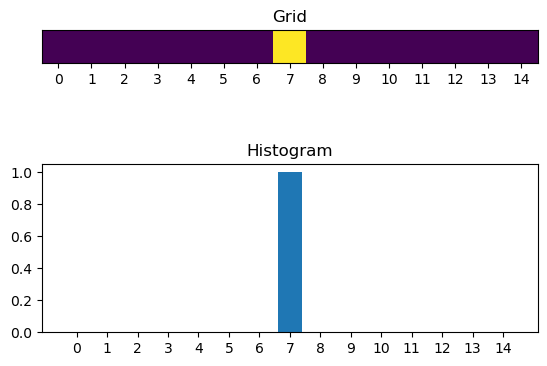

In [8]:
from ex2_1 import *
%matplotlib inline

belief = np.zeros(15)

# initial known position
x_start = 7
belief[x_start] = 1.0

plot_belief(belief)

The plots above shows the initial belief about the position of the robot both as weights in the grid world and as a histogram.

1. **[4.0]** Implement the motion model (`motion_model`) and estimate recursively the belief about the position of the robot after executing the following sequence of commands: 
$$ F, F, F, F, B, B, F, F, B $$
Plot the final belief using the `plot_belief` function.

The most likely position of the robot is at index: 13


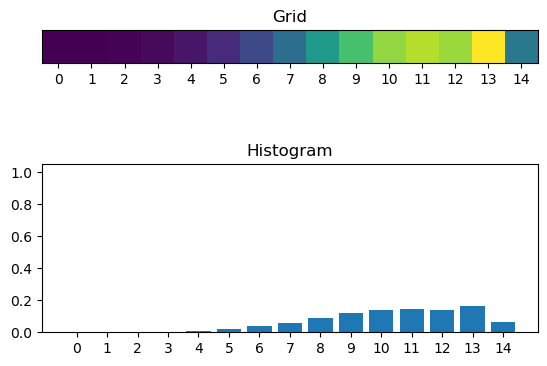

In [6]:
# Execute the sequence of commands: F, F, F, F, B, B, F, F, B
commands = ['F', 'F', 'F', 'F', 'B', 'B', 'F', 'F', 'B']

# Apply the motion model recursively
for command in commands:
    belief = motion_model(command, belief)

# Plot the final belief
plot_belief(belief)

print("The most likely position of the robot is at index:", np.argmax(belief))


This cell applies the motion model sequentially for the given action list, which is exactly how a recursive prediction step works in a Bayes filter. Propagating the belief through each command captures accumulated uncertainty from actuation noise. Plotting the resulting belief makes it easy to verify that probability mass shifts in the expected direction and spreads over neighboring cells.

---

## Bayes filter

Now, assume that we equipped the robot with a sensor which is able to recognize the color of the floor on which the robot navigates.

The floor can be either black **(0)** or white **(1)** and the environment looks as follows:

![gridworld_map](./pics/1d_gridworld_floor.png)

The map of the floor colors is stored in `world.data`.

The sensor is able to recognize that:

- a tile is **white** with probability **0.7** 
- a tile is **black** with probability **0.9** 

The robot starts again in `7`. It executes the same commands as in 1. and follows the same motion model.

During navigation, it makes the observations stored in `observations.data`.

Thanks to its new sensor, it can now use the obrvations to estimate its position in the world.


2. **[3.5]** Implement the function `sensor_model` which defines the sensor model and implement `recursive_bayes_filter` fucntion which estimates recursively the belief about the position of the robot incorporating the observations.
Plot the final belief using the `plot_belief` function.

3. **[0.5]** Print out the most likely position and the corresponding probability.

Most likely position: 9
Corresponding probability: 0.2386


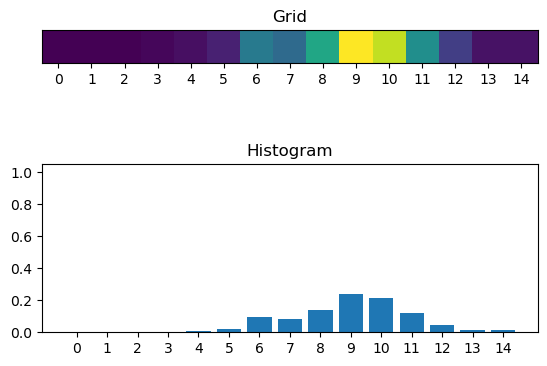

In [ ]:

# Reload the module to get the new functions
import importlib
import ex2_1
importlib.reload(ex2_1)
from ex2_1 import *

# Load world and observations data
class DataWrapper:
    def __init__(self, data):
        self.data = np.array([int(x.strip()) for x in data])

with open('world.data', 'r') as f:
    world_data = f.read().strip().split(',')
    world = DataWrapper(world_data)

with open('observations.data', 'r') as f:
    obs_data = f.read().strip().split(',')
    observations = DataWrapper(obs_data)

# Reset belief to known initial position
belief = np.zeros(15)
belief[7] = 1.0

# Apply recursive Bayes filter
commands = ['F', 'F', 'F', 'F', 'B', 'B', 'F', 'F', 'B']
belief = recursive_bayes_filter(commands, observations.data, belief, world)

# Plot final belief
plot_belief(belief)

# Task 3: Print the most likely position and its probability
most_likely_pos = np.argmax(belief)
max_probability = np.max(belief)
print(f"Most likely position: {most_likely_pos}")
print(f"Corresponding probability: {max_probability:.4f}")


This cell loads the map and observations, then runs the full Bayes filter by alternating motion updates and sensor corrections. This mirrors the standard probabilistic robotics pipeline: predict with dynamics, then correct with measurements. Printing the MAP estimate (`argmax`) and its probability provides a clear summary statistic of the final belief.

---

## Bayes filter with unknown initial position


What if the initial position of the robot is unknown?

Consider the same task as in 2. but with the initial belief about the position of the robot being an uniform probability distribution over the world.

2. **[1.5]** Plot the final belief about the position of the robot.

3. **[0.5]** Print out the most likely position and the corresponding probability.

Most likely position: 14
Corresponding probability: 0.1204


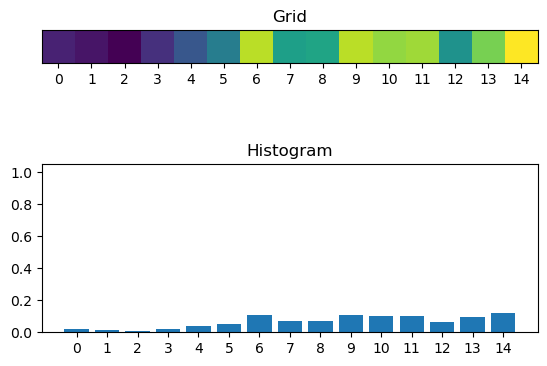

In [ ]:

# Reload the module
import importlib
import ex2_1
importlib.reload(ex2_1)
from ex2_1 import *

# Initialize belief with uniform distribution (unknown initial position)
belief = np.ones(15) / 15  # Equal probability for all positions

# Load world and observations data
class DataWrapper:
    def __init__(self, data):
        self.data = np.array([int(x.strip()) for x in data])

with open('world.data', 'r') as f:
    world_data = f.read().strip().split(',')
    world = DataWrapper(world_data)

with open('observations.data', 'r') as f:
    obs_data = f.read().strip().split(',')
    observations = DataWrapper(obs_data)

# Apply recursive Bayes filter with unknown initial position
commands = ['F', 'F', 'F', 'F', 'B', 'B', 'F', 'F', 'B']
belief = recursive_bayes_filter(commands, observations.data, belief, world)

# Plot the final belief
plot_belief(belief)

# Task 3: Print the most likely position and probability
most_likely_pos = np.argmax(belief)
max_probability = np.max(belief)
print(f"Most likely position: {most_likely_pos}")
print(f"Corresponding probability: {max_probability:.4f}")


Here the prior is uniform to represent complete uncertainty about the start position. This is the correct modeling choice when no initial localization information is available. Running the same Bayes filter then shows how observations and motion alone can concentrate the belief over time, and the MAP output summarizes the most likely final location.

## Belief Evolution Visualization

Extend your Bayes filter implementation to visualize how the belief evolves over time. Implement functions to compute and store beliefs after each motion update and sensor measurement.

- Compute two belief trajectories:
  - **Motion-only**: Apply motion model recursively without sensor updates (odometry propagation only).
  - **Full Bayes**: Incorporate both motion model and sensor model as before.
- Use the same command sequence and observations from Task 2.
- Plot the belief histograms (using `plotbelief`) for 5 evenly spaced time steps (e.g., initial, after 20%, 40%, 60%, 100% of steps).
- Overlay motion-only (dashed lines) and full Bayes (solid lines) on the same figure for comparison.

**Task (2.5 points):** Generate a multi-panel plot showing belief evolution. Discuss how sensor measurements reduce uncertainty compared to odometry alone.


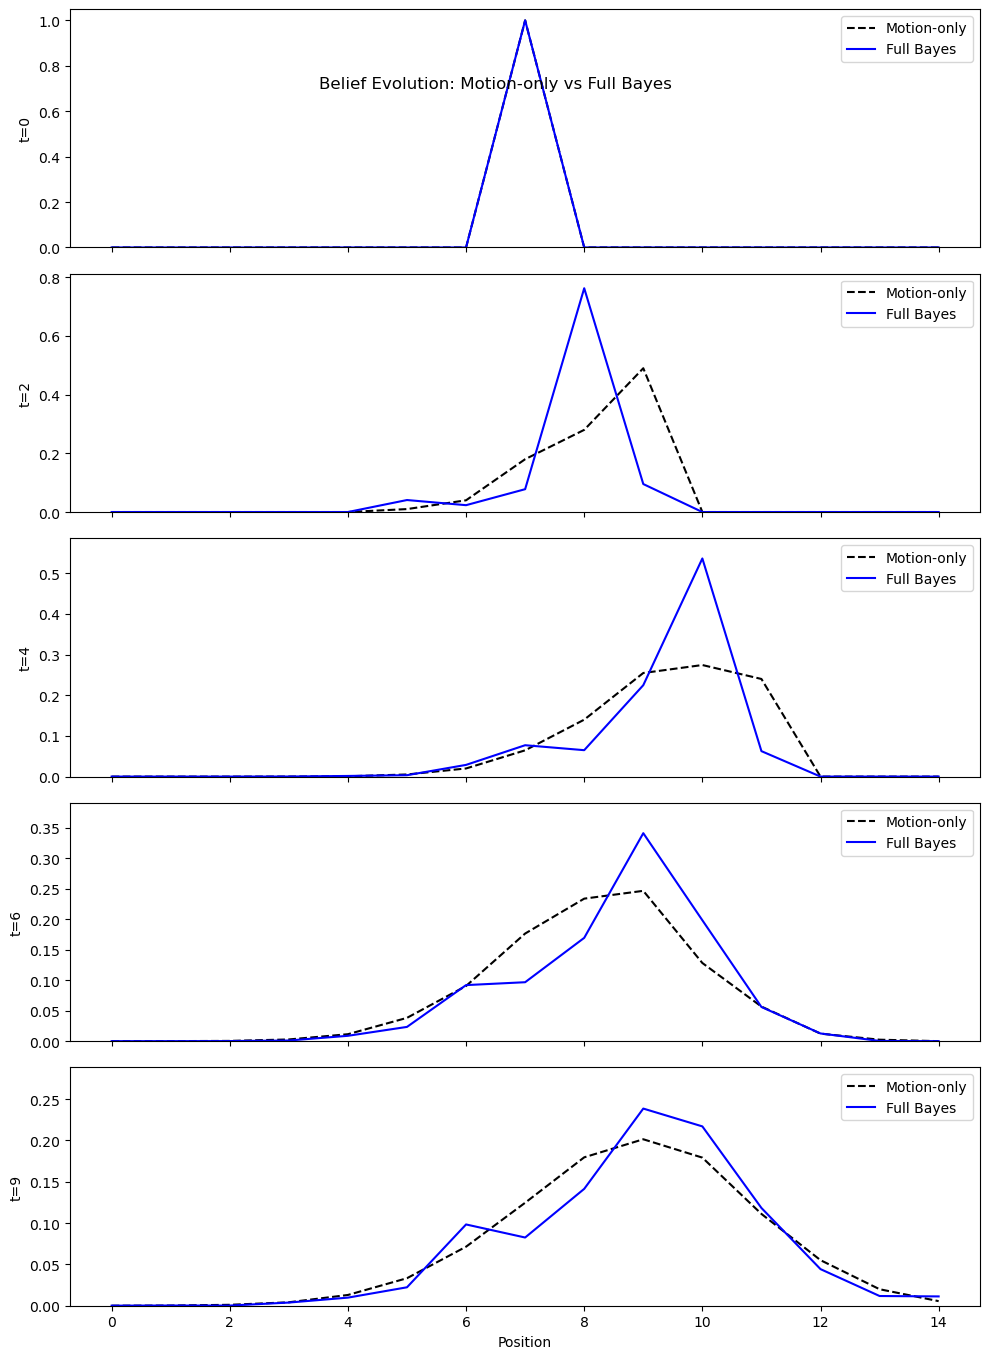

In [17]:

# Belief Evolution Visualization
import importlib
import ex2_1
importlib.reload(ex2_1)
from ex2_1 import *

# Load world and observations data
class DataWrapper:
    def __init__(self, data):
        self.data = np.array([int(x.strip()) for x in data])

with open('world.data', 'r') as f:
    world_data = f.read().strip().split(',')
    world = DataWrapper(world_data)

with open('observations.data', 'r') as f:
    obs_data = f.read().strip().split(',')
    observations = DataWrapper(obs_data)

commands = ['F', 'F', 'F', 'F', 'B', 'B', 'F', 'F', 'B']

# Initial belief (known start at 7)
belief_init = np.zeros(15)
belief_init[7] = 1.0

# Trajectories
beliefs_motion = [belief_init.copy()]
beliefs_full = [belief_init.copy()]

belief_motion = belief_init.copy()
belief_full = belief_init.copy()

for action, obs in zip(commands, observations.data):
    belief_motion = motion_model(action, belief_motion)
    beliefs_motion.append(belief_motion.copy())

    belief_full = motion_model(action, belief_full)
    belief_full = sensor_model(obs, belief_full, world)
    beliefs_full.append(belief_full.copy())

# Select 5 evenly spaced time steps (including initial and final)
num_steps = len(commands)
time_indices = np.linspace(0, num_steps, 5, dtype=int)

# Plot belief evolution
fig, axes = plt.subplots(5, 1, figsize=(10, 14), sharex=True)
positions = np.arange(0, belief_init.shape[0])

for ax, idx in zip(axes, time_indices):
    ax.plot(positions, beliefs_motion[idx], 'k--', label='Motion-only')
    ax.plot(positions, beliefs_full[idx], 'b-', label='Full Bayes')
    ax.set_ylim(0, max(beliefs_full[idx].max(), beliefs_motion[idx].max()) + 0.05)
    ax.set_ylabel(f"t={idx}")
    ax.legend(loc='upper right')

axes[-1].set_xlabel('Position')
fig.suptitle('Belief Evolution: Motion-only vs Full Bayes', y=0.92)
plt.tight_layout()


This cell compares uncertainty growth under pure motion against the full Bayes filter with measurements. Storing trajectories at each step makes the evolution explicit, and plotting multiple time slices highlights how sensor updates sharpen the belief relative to odometry alone. The dashed vs solid overlay is a clear visual diagnostic for measurement impact.


## Unknown Initial Position with Gaussian Prior

Modify the unknown initial position scenario from the original assignment.

- Replace the uniform prior with a Gaussian prior centered at cell 10 (for a 21-cell grid), standard deviation σ=3.
- Normalize the prior to sum to 1: `prior = np.exp(-0.5 * ((np.arange(21) - 10) / 3)**2); prior /= prior.sum()`
- Use the same motion model, commands, sensor model, and observations as in Task 2.

**Task (2.0 points):** Plot the final belief using `plotbelief`. Print the most likely position and its probability (e.g., `np.argmax(belief), np.max(belief)`).

This demonstrates how informative priors aid localization in probabilistic robotics. 

Most likely position: 14
Corresponding probability: 0.1838


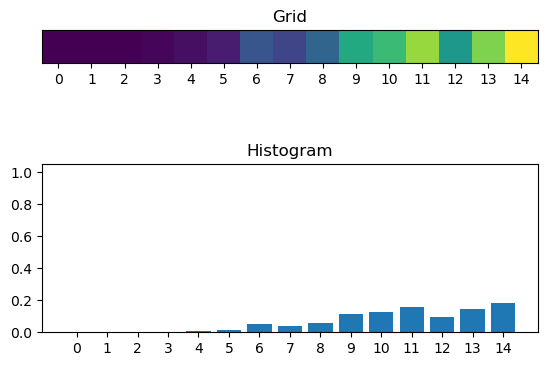

In [13]:
# Unknown Initial Position with Gaussian Prior

import importlib
import ex2_1
importlib.reload(ex2_1)
from ex2_1 import *

# Load world and observations data
class DataWrapper:
    def __init__(self, data):
        self.data = np.array([int(x.strip()) for x in data])

with open('world.data', 'r') as f:
    world_data = f.read().strip().split(',')
    world = DataWrapper(world_data)

with open('observations.data', 'r') as f:
    obs_data = f.read().strip().split(',')
    observations = DataWrapper(obs_data)

# Gaussian prior (centered at cell 10, sigma=3)
n = len(world.data)
center = 10
sigma = 3.0
prior = np.exp(-0.5 * ((np.arange(n) - center) / sigma) ** 2)
prior /= prior.sum()

belief = prior.copy()

# Apply recursive Bayes filter
commands = ['F', 'F', 'F', 'F', 'B', 'B', 'F', 'F', 'B']
belief = recursive_bayes_filter(commands, observations.data, belief, world)

# Plot final belief and print most likely position
plot_belief(belief)
most_likely_pos = np.argmax(belief)
max_probability = np.max(belief)
print(f"Most likely position: {most_likely_pos}")
print(f"Corresponding probability: {max_probability:.4f}")


This cell replaces the uniform prior with a Gaussian prior to encode informed expectations about the start location. Normalization ensures a valid probability distribution, and then the Bayes filter integrates this prior with motion and sensor data. The final MAP estimate shows how a stronger prior can bias and often improve localization when consistent with observations.